# NIFTY 50: A 10-Year Analysis of Returns, Risk & Market Behaviour 

## Project Objective

This project analyzes historical NIFTY 50 index data sourced from NSE India, covering 1 April 2016 to 30 Mar 2026, to explore long-term performance, daily returns, volatility, drawdowns and hypothetical investment outcomes.

### Questions I want to explore 

- How did the NIFTY 50 index level change over the observed period?
- Which complete calendar years were the strongest & weakest periods?
- How did the daily returns behave, and what were the most extreme trading days?
- When was market volatility highest?
- What was the largest drawdown, and how long did recovery take?
- How would a hypothetical ₹1 Lakh tracking the NIFTY 50 index-level movement have changed?
- How would the ending hypothetical value change if the strongest daily - return observations were missed?

## Data Source

The historical index data used in this project was downloaded from NSE India's Historical Index Data section.

**Index:** NIFTY 50
**Coverage:** 1 April 2016 to 30 March 2026
**Raw data:** Yearly CSV files
**Primary fields:** Date, Open, High, Low, Close, Shares Traded and Turnover (₹ Cr)

The original yearly files are preserved in `data/raw/`, while the cleaned and combined dataset is stored in `data/processed/`.

## Environment & Libraries

The analysis uses Pandas and NumPy for data manipulation and calculations, with Matplotlib and Seaborn for visualisation.

In [159]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [160]:
# Loading the CSV Files of Nifty 50 data

data_path = Path("../data/raw")

csv_files = sorted(data_path.glob("*.csv"))

print(f"Number of CSV files found: {len(csv_files)}")

for file in csv_files:
    print (file.name)

Number of CSV files found: 10
nifty50_2016.csv
nifty50_2017.csv
nifty50_2018.csv
nifty50_2019.csv
nifty50_2020.csv
nifty50_2021.csv
nifty50_2022.csv
nifty50_2023.csv
nifty50_2024.csv
nifty50_2025.csv


In [162]:
# Inspecting a sample NSE file
# Before combining all yearly CSV files I inspected one file to understanf it's structure, columns and data types.

sample = pd.read_csv("../data/raw/nifty50_2016.csv")
sample.head()

,Date,Open,High,Low,Close,Shares Traded,Turnover (₹ Cr)
0,31-MAR-2017,9158.90,9191.70,9152.10,9173.75,196771674,10955.05
1,30-MAR-2017,9142.60,9183.15,9136.35,9173.75,333410368,15585.42
2,29-MAR-2017,9128.70,9153.15,9109.10,9143.80,250902906,11089.43
3,28-MAR-2017,9081.50,9110.40,9079.80,9100.80,188985603,8139.28
4,27-MAR-2017,9093.45,9094.85,9024.65,9045.20,209036051,8921.57


### Column Structure

In [163]:
sample.columns

Index(['Date ', 'Open ', 'High ', 'Low ', 'Close ', 'Shares Traded ',
       'Turnover (₹ Cr)'],
      dtype='str')

### Initial Data Types

In [164]:
sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 248 entries, 0 to 247
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Date             248 non-null    str    
 1   Open             248 non-null    float64
 2   High             248 non-null    float64
 3   Low              248 non-null    float64
 4   Close            248 non-null    float64
 5   Shares Traded    248 non-null    int64  
 6   Turnover (₹ Cr)  248 non-null    float64
dtypes: float64(5), int64(1), str(1)
memory usage: 13.7 KB


### Sample Dataset Dimensions 

The sample file contains 248 trading-day observations across 7 columns

In [19]:
sample.shape

(248, 7)

In [21]:
# Checking all the CSV structures 

for file in csv_files:
    temp_df = pd.read_csv(file)
    print(file.name, temp_df.shape, list(temp_df.columns))

nifty50_2016.csv (248, 7) ['Date ', 'Open ', 'High ', 'Low ', 'Close ', 'Shares Traded ', 'Turnover (₹ Cr)']
nifty50_2017.csv (246, 7) ['Date ', 'Open ', 'High ', 'Low ', 'Close ', 'Shares Traded ', 'Turnover (₹ Cr)']
nifty50_2018.csv (248, 7) ['Date ', 'Open ', 'High ', 'Low ', 'Close ', 'Shares Traded ', 'Turnover (₹ Cr)']
nifty50_2019.csv (247, 7) ['Date ', 'Open ', 'High ', 'Low ', 'Close ', 'Shares Traded ', 'Turnover (₹ Cr)']
nifty50_2020.csv (249, 7) ['Date ', 'Open ', 'High ', 'Low ', 'Close ', 'Shares Traded ', 'Turnover (₹ Cr)']
nifty50_2021.csv (248, 7) ['Date ', 'Open ', 'High ', 'Low ', 'Close ', 'Shares Traded ', 'Turnover (₹ Cr)']
nifty50_2022.csv (249, 7) ['Date ', 'Open ', 'High ', 'Low ', 'Close ', 'Shares Traded ', 'Turnover (₹ Cr)']
nifty50_2023.csv (245, 7) ['Date ', 'Open ', 'High ', 'Low ', 'Close ', 'Shares Traded ', 'Turnover (₹ Cr)']
nifty50_2024.csv (249, 7) ['Date ', 'Open ', 'High ', 'Low ', 'Close ', 'Shares Traded ', 'Turnover (₹ Cr)']
nifty50_2025.csv (2

## Combining the Yearly Datasets 

After confirming that all yearly CSV files share the same column structure, the files can be concatenated into a single dataframe for anaysis.

In [165]:
dataframes = []

for file in csv_files:
    temp_df = pd.read_csv(file)
    dataframes.append(temp_df)

df = pd.concat(dataframes, ignore_index = True)


In [166]:
print("Combined dataset shape:", df.shape)

Combined dataset shape: (2476, 7)


### Inspecting the Combined Dataset

After combining all yearly files, I inspected both the beginning and end of the dataframe to verify that the records were loaded correctly before proceeding with Cleaning & Validation.

In [169]:
# Checking the top and bottom rows of the dataset 

display(df.head())
display(df.tail())

,Date,Open,High,Low,Close,Shares Traded,Turnover (₹ Cr)
0,31-MAR-2017,9158.90,9191.70,9152.10,9173.75,196771674,10955.05
1,30-MAR-2017,9142.60,9183.15,9136.35,9173.75,333410368,15585.42
2,29-MAR-2017,9128.70,9153.15,9109.10,9143.80,250902906,11089.43
3,28-MAR-2017,9081.50,9110.40,9079.80,9100.80,188985603,8139.28
4,27-MAR-2017,9093.45,9094.85,9024.65,9045.20,209036051,8921.57


,Date,Open,High,Low,Close,Shares Traded,Turnover (₹ Cr)
2471,07-APR-2025,21758.4,22254.00,21743.65,22161.60,647107618,49172.14
2472,04-APR-2025,23190.4,23214.70,22857.45,22904.45,466776198,33761.96
2473,03-APR-2025,23150.3,23306.50,23145.80,23250.10,283196379,23501.33
2474,02-APR-2025,23192.6,23350.00,23158.45,23332.35,340970371,24334.30
2475,01-APR-2025,23341.1,23565.15,23136.40,23165.70,375118343,30680.70


In [30]:
df.columns

Index(['Date ', 'Open ', 'High ', 'Low ', 'Close ', 'Shares Traded ',
       'Turnover (₹ Cr)'],
      dtype='str')

### Cleaning Column Names

The NSE files contained trailing spaces in several column names, such as 'Date ' and 'Close '.These spaces can cause errors when referencing columns in python, so they are removed before further analysis.

In [34]:
df.columns = df.columns.str.strip()
df.columns.tolist()

['Date', 'Open', 'High', 'Low', 'Close', 'Shares Traded', 'Turnover (₹ Cr)']

In [ ]:
df["Date"] = pd.to_datetime(df["Date"], errors = "coerce")

In [41]:
print("Start Date: ",df["Date"].min())
print("End Date: ",df['Date'].max())
print("Invalid Dates: ",df['Date'].isnull().sum())

Start Date:  2016-04-01 00:00:00
End Date:  2026-03-30 00:00:00
Invalid Dates:  0


In [45]:
# Sorting the data to check if there are any duplicates 

df = df.sort_values("Date").reset_index(drop = True)
df['Date'].head()
df['Date'].tail()


2471   2026-03-23
2472   2026-03-24
2473   2026-03-25
2474   2026-03-27
2475   2026-03-30
Name: Date, dtype: datetime64[us]

In [46]:
# Checking if there are any duplicated dates wherein the values are getting double 

df['Date'].duplicated().sum()

np.int64(0)

In [47]:
# Checking if there are any missing values 

df.isnull().sum()

Date               0
Open               0
High               0
Low                0
Close              0
Shares Traded      0
Turnover (₹ Cr)    0
dtype: int64

In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2476 entries, 0 to 2475
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             2476 non-null   datetime64[us]
 1   Open             2476 non-null   float64       
 2   High             2476 non-null   float64       
 3   Low              2476 non-null   float64       
 4   Close            2476 non-null   float64       
 5   Shares Traded    2476 non-null   int64         
 6   Turnover (₹ Cr)  2476 non-null   float64       
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 135.5 KB


In [49]:
# Checking the Descriptive Stats of the dataset 

df.describe()

,Date,Open,High,Low,Close,Shares Traded,Turnover (₹ Cr)
count,2476,2476.000000,2476.000000,2476.000000,2476.000000,2.476000e+03,2476.000000
mean,2021-04-01 00:41:17.544426,15569.298768,15639.279766,15476.800202,15559.617912,3.477591e+08,22463.720384
min,2016-04-01 00:00:00,7542.350000,7569.350000,7511.100000,7546.450000,1.661087e+07,805.890000
25%,2018-09-30 06:00:00,10645.025000,10697.550000,10586.512500,10627.275000,2.255870e+08,14578.832500
50%,2021-03-31 12:00:00,14860.400000,14928.725000,14724.200000,14865.950000,2.879762e+08,21593.780000
75%,2023-09-28 06:00:00,19640.637500,19719.912500,19562.987500,19661.100000,4.200013e+08,28842.992500
max,2026-03-30 00:00:00,26333.700000,26373.200000,26210.050000,26328.550000,1.811564e+09,93786.440000
std,NaN,5698.315936,5719.557581,5675.461832,5697.569887,1.856707e+08,10614.283054


In [50]:
# Checking the OHLC Record | For a normal OHLC record, the High should not be below Low 

# Are there any trading days where the recorded High is lower than the recorded low?

(df['High'] < df['Low']).sum()

np.int64(0)

In [51]:
# Saving the merged and the Clean Datasets post all the sanity checks to our processed folder

output_path = Path("/Users/roshni/nifty50-analysis/data/processed/nifty50_clean.csv")

df.to_csv(output_path, index = False)

print("Clean Dataset saved sucessfully!")


Clean Dataset saved sucessfully!


# Analysis : 01
## How did the Nifty 50 Index level change between 1 Apr 2016 and 30 Mar 2026?

In [53]:
# Checking the starting values 

df[['Date','Close']].head()

,Date,Close
0,2016-04-01,7713.05
1,2016-04-04,7758.80
2,2016-04-05,7603.20
3,2016-04-06,7614.35
4,2016-04-07,7546.45


In [54]:
# Checking the ending values 

df[['Date','Close']].tail()

,Date,Close
2471,2026-03-23,22512.65
2472,2026-03-24,22912.40
2473,2026-03-25,23306.45
2474,2026-03-27,22819.60
2475,2026-03-30,22331.40


In [58]:
# Extracting the exact starting & ending values 

start_date = df['Date'].iloc[0]
end_date = df['Date'].iloc[-1]

start_close = df['Close'].iloc[0]
end_close = df['Close'].iloc[-1]

print("Start Date: ",start_date)
print("End Date: ",end_date)

print("Starting Close: ",start_close)
print("Ending Close: ",end_close)


Start Date:  2016-04-01 00:00:00
End Date:  2026-03-30 00:00:00
Starting Close:  7713.05
Ending Close:  22331.4


In [61]:
# Analysis 1.1 | Total Percentage Change 

total_return = ((end_close / start_close) - 1) * 100

print(f"Total Nifty 50 Change: {total_return: .2f}%")

Total Nifty 50 Change:  189.53%


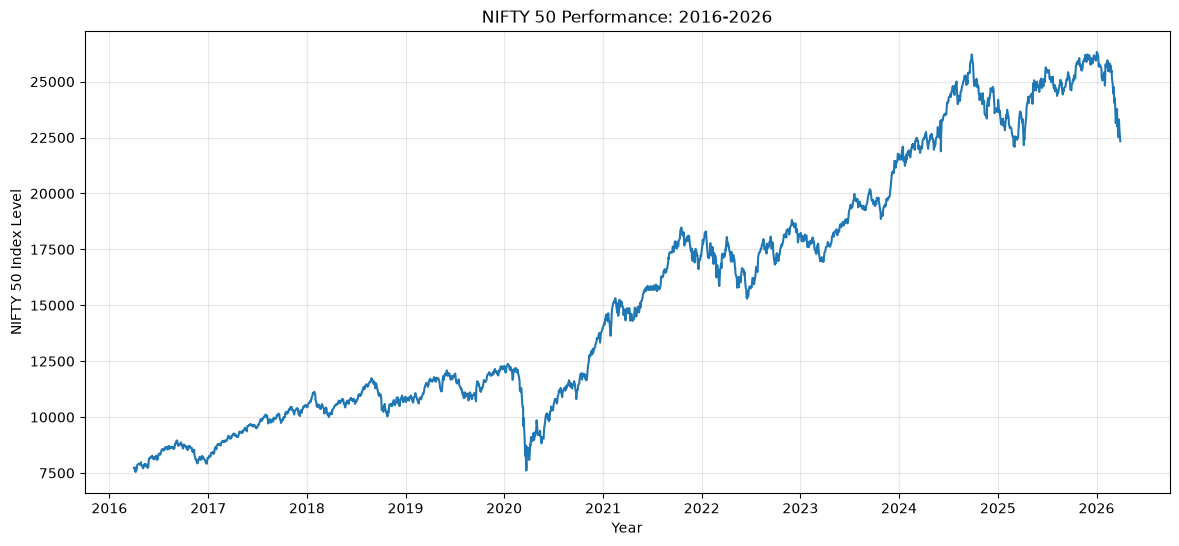

In [62]:
plt.figure(figsize = (14,6))

plt.plot(df['Date'],df['Close'])
plt.title("NIFTY 50 Performance: 2016-2026")
plt.xlabel("Year")
plt.ylabel("NIFTY 50 Index Level")

plt.grid(alpha = 0.3)
plt.show()

### Initial Observation 

- The NIFTY 50 Index level increased by 189.53 % between 1st April'2016 and 30th Mar'2026.
- Despite the upward trend, the movement was not consistent.
- A particularly sharp decline is visible around 2020.
- There are several other periods of decline and recovery throughout the dataset. 

Next, we will analyse returns & drawdowns to quantify these movements rather than relying only on visual observation. 


In [63]:
# Calculating daily returns 

df['Daily_Return'] = df['Close'].pct_change()

In [66]:
df[['Date','Close','Daily_Return']].head(10)

,Date,Close,Daily_Return
0,2016-04-01,7713.05,NaN
1,2016-04-04,7758.80,0.005932
2,2016-04-05,7603.20,-0.020055
3,2016-04-06,7614.35,0.001466
4,2016-04-07,7546.45,-0.008917
5,2016-04-08,7555.20,0.001159
6,2016-04-11,7671.40,0.015380
7,2016-04-12,7708.95,0.004895
8,2016-04-13,7850.45,0.018355
9,2016-04-18,7914.70,0.008184


In [67]:
df['Daily_Return_Pct'] = df['Daily_Return']*100

In [68]:
df[['Date','Close','Daily_Return_Pct']].head(10)

,Date,Close,Daily_Return_Pct
0,2016-04-01,7713.05,NaN
1,2016-04-04,7758.80,0.593151
2,2016-04-05,7603.20,-2.005465
3,2016-04-06,7614.35,0.146649
4,2016-04-07,7546.45,-0.891737
5,2016-04-08,7555.20,0.115949
6,2016-04-11,7671.40,1.538014
7,2016-04-12,7708.95,0.489480
8,2016-04-13,7850.45,1.835529
9,2016-04-18,7914.70,0.818424


In [71]:
# Finding the best & The Worst Trading Days 

best_day = df.loc[df["Daily_Return"].idxmax()]
worst_day = df.loc[df["Daily_Return"].idxmin()]

In [74]:
print("Best Trading Day")
print("Date: ",best_day["Date"])
print(f"Return: {best_day['Daily_Return_Pct']:2f}%")

print("\nWorst Trading Day")
print("Date: ",worst_day["Date"])
print(f"Return: {worst_day['Daily_Return_Pct']:2f}%")

Best Trading Day
Date:  2020-04-07 00:00:00
Return: 8.763205%

Worst Trading Day
Date:  2020-03-23 00:00:00
Return: -12.980464%


In [75]:
# Checking for the normal trading days as compare with the extreme days 

df['Daily_Return_Pct'].describe()

count    2475.000000
mean        0.048194
std         1.018975
min       -12.980464
25%        -0.415858
50%         0.070314
75%         0.572698
max         8.763205
Name: Daily_Return_Pct, dtype: float64

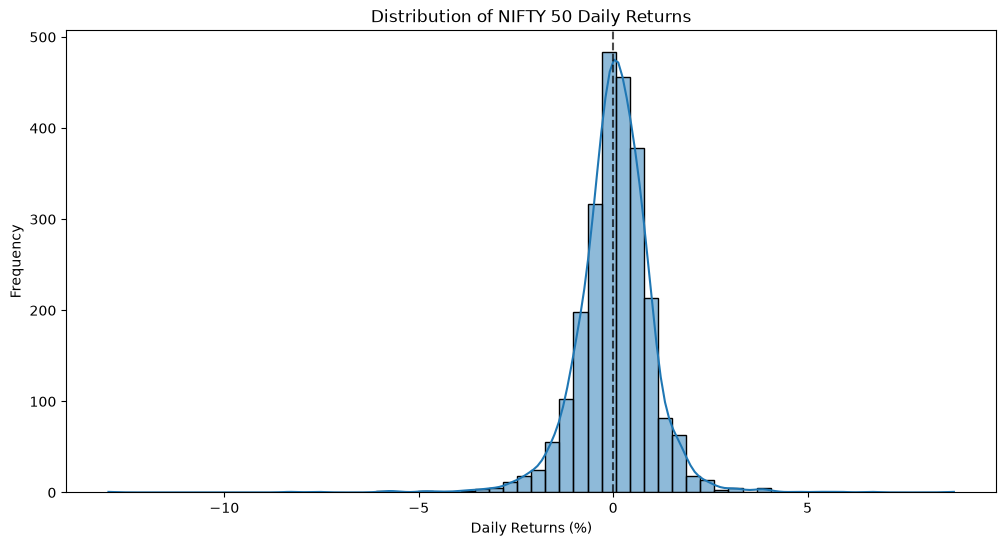

In [78]:
# Visualising the Distribution of Daily Returns 

plt.figure(figsize = (12,6))

sns.histplot(
    df["Daily_Return_Pct"].dropna(),
    bins = 60,
    kde = True
)
plt.axvline(0, color = "black", linestyle = "--", alpha = 0.7)

plt.title("Distribution of NIFTY 50 Daily Returns")
plt.xlabel("Daily Returns (%)")
plt.ylabel("Frequency")

plt.show()

In [79]:
# Analysing the Annual Returns across 10 yrs 

year_end_close = (
    df.set_index("Date")["Close"]
    .resample("YE")
    .last()
)

year_end_close

Date
2016-12-31     8185.80
2017-12-31    10530.70
2018-12-31    10862.55
2019-12-31    12168.45
2020-12-31    13981.75
2021-12-31    17354.05
2022-12-31    18105.30
2023-12-31    21731.40
2024-12-31    23644.80
2025-12-31    26129.60
2026-12-31    22331.40
Freq: YE-DEC, Name: Close, dtype: float64

In [80]:
annual_returns = year_end_close.pct_change() * 100
annual_returns

Date
2016-12-31          NaN
2017-12-31    28.645948
2018-12-31     3.151262
2019-12-31    12.022039
2020-12-31    14.901651
2021-12-31    24.119298
2022-12-31     4.328961
2023-12-31    20.027837
2024-12-31     8.804771
2025-12-31    10.508865
2026-12-31   -14.536005
Freq: YE-DEC, Name: Close, dtype: float64

In [84]:
# Evaluating the complete annual years data, excluding the 2026 data since the data is getting ended at 30th Mar'26 which can result in partial data 

complete_annual_returns = annual_returns.loc["2017":"2025"]
complete_annual_returns

Date
2017-12-31    28.645948
2018-12-31     3.151262
2019-12-31    12.022039
2020-12-31    14.901651
2021-12-31    24.119298
2022-12-31     4.328961
2023-12-31    20.027837
2024-12-31     8.804771
2025-12-31    10.508865
Freq: YE-DEC, Name: Close, dtype: float64

In [93]:
best_year = complete_annual_returns.idxmax()
weakest_year = complete_annual_returns.idxmin()

print(f"Best Year:",best_year.year)
print(f"Return: {complete_annual_returns.loc[best_year]:.2f}%")

print(f"\nWeakest Year:",weakest_year.year)
print(f"Return: {complete_annual_returns.loc[weakest_year]:.2f}%")

Best Year: 2017
Return: 28.65%

Weakest Year: 2018
Return: 3.15%


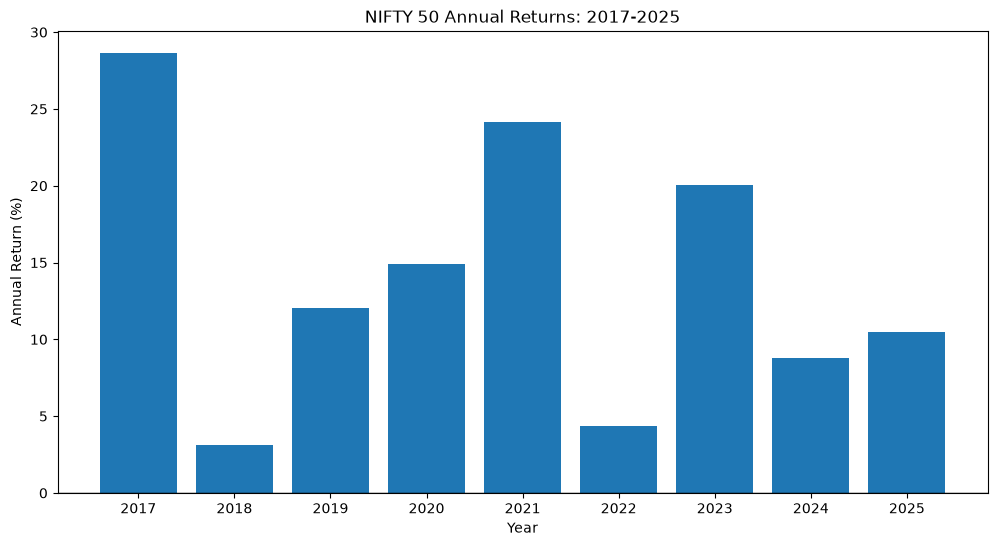

In [94]:
# Visualising the Annual report bar chart 

plt.figure(figsize = (12,6))

plt.bar(
    complete_annual_returns.index.year,
    complete_annual_returns.values 
)

plt.axhline(0, color = 'black', linewidth = 1)

plt.title('NIFTY 50 Annual Returns: 2017-2025')
plt.xlabel("Year")
plt.ylabel("Annual Return (%)")

plt.xticks(complete_annual_returns.index.year)

plt.show()

In [97]:
# Analysis 4 - Volatility | An important concept which explains something annual returns couldn't tell us, how stable or turbulent the joruney was 

rolling_std_21 = df["Daily_Return"].rolling(window=21).std()

df['Rolling_21D_Std'] = rolling_std_21

df[['Date','Daily_Return','Rolling_21D_Std']].head(25)

,Date,Daily_Return,Rolling_21D_Std
0,2016-04-01,NaN,NaN
1,2016-04-04,0.005932,NaN
2,2016-04-05,-0.020055,NaN
3,2016-04-06,0.001466,NaN
4,2016-04-07,-0.008917,NaN
5,2016-04-08,0.001159,NaN
6,2016-04-11,0.015380,NaN
7,2016-04-12,0.004895,NaN
8,2016-04-13,0.018355,NaN
9,2016-04-18,0.008184,NaN


In [98]:
# Annualising the Volatility
# In Financial Analysis, Volatility is often expressed on an annualised basis.
# A common used approximation is about 252 trading sessions per year
# We convert the daily volatility into annualised volatility using 
## Annualised Volatility = Daily Volatility * Sqrt of 252 

df['Rolling_Volatility_21D'] = (
    df['Daily_Return']
    .rolling(window=21)
    .std()
    * np.sqrt(252)
    * 100
)

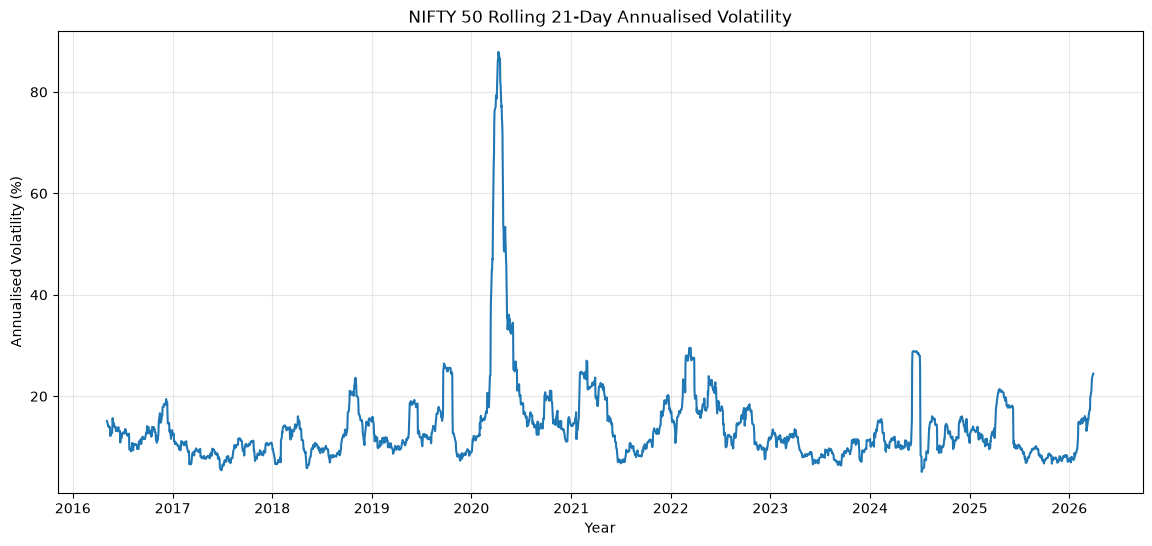

In [99]:
plt.figure (figsize = (14,6))

plt.plot(
    df["Date"],
    df["Rolling_Volatility_21D"]
)

plt.title("NIFTY 50 Rolling 21-Day Annualised Volatility")
plt.xlabel("Year")
plt.ylabel("Annualised Volatility (%)")

plt.grid(alpha = 0.3)
plt.show()

In [105]:
# Calculating the highest-volatility observation 

peak_vol_idx = df['Rolling_Volatility_21D'].idxmax()
peak_row = df.loc[peak_vol_idx]
peak_row

Date                      2020-04-09 00:00:00
Open                                  8973.05
High                                  9128.35
Low                                   8904.55
Close                                  9111.9
Shares Traded                       743036134
Turnover (₹ Cr)                      32907.82
Daily_Return                         0.041509
Daily_Return_Pct                     4.150879
Rolling_21D_Std                      0.055365
Rolling_Volatility_21D              87.888746
Name: 993, dtype: object

In [107]:
peak_volatility_date = peak_row['Date']
peak_volatility = peak_row['Rolling_Volatility_21D']

print(f"Peak Volatility Date:", peak_volatility_date.date())
print(f"Peak 21-Day Annualised Volatility: {peak_volatility:.2f}%")

Peak Volatility Date: 2020-04-09
Peak 21-Day Annualised Volatility: 87.89%


In [113]:
# Analysis 5 | Drawdown Analysis 
# From a previous NIFTY 50 peak, how far did the index fall before recovering?

#Volatility?
#How strongly were the returns fluctuating?

#Drawdown?
#How far are we below the highest level reached so far?

# Calculating the Running Peak 

df['Running_Peak'] = df['Close'].cummax()

df[['Date','Close','Running_Peak']].head(20)

,Date,Close,Running_Peak
0,2016-04-01,7713.05,7713.05
1,2016-04-04,7758.80,7758.80
2,2016-04-05,7603.20,7758.80
3,2016-04-06,7614.35,7758.80
4,2016-04-07,7546.45,7758.80
5,2016-04-08,7555.20,7758.80
6,2016-04-11,7671.40,7758.80
7,2016-04-12,7708.95,7758.80
8,2016-04-13,7850.45,7850.45
9,2016-04-18,7914.70,7914.70


In [114]:
# Calculating the drawdown now

df['Drawdown'] = (
    df['Close'] / df['Running_Peak'] - 1
)

df['Drawdown_Pct'] = df['Drawdown'] * 100

df[['Date','Close','Running_Peak','Drawdown_Pct']].head(20)

,Date,Close,Running_Peak,Drawdown_Pct
0,2016-04-01,7713.05,7713.05,0.000000
1,2016-04-04,7758.80,7758.80,0.000000
2,2016-04-05,7603.20,7758.80,-2.005465
3,2016-04-06,7614.35,7758.80,-1.861757
4,2016-04-07,7546.45,7758.80,-2.736892
5,2016-04-08,7555.20,7758.80,-2.624117
6,2016-04-11,7671.40,7758.80,-1.126463
7,2016-04-12,7708.95,7758.80,-0.642496
8,2016-04-13,7850.45,7850.45,0.000000
9,2016-04-18,7914.70,7914.70,0.000000


In [118]:
# Evaluating the maximum Drawdown

max_drawdown_idx = df['Drawdown_Pct'].idxmin()

max_drawdown_row = df.loc[max_drawdown_idx]

print(f"Maximum Drawdown Date:",max_drawdown_row['Date'].date())
print(f"Maximum Drawdown: {max_drawdown_row['Drawdown_Pct']:.2f}%")
print(f"NIFTY Close: {max_drawdown_row['Close']:.2f}")

Maximum Drawdown Date: 2020-03-23
Maximum Drawdown: -38.44%
NIFTY Close: 7610.25


In [120]:
# Finding the peak before the drawdown 

peak_value = max_drawdown_row['Running_Peak']

print(f"Previous Peak Level: {peak_value:.2f}")

Previous Peak Level: 12362.30


In [124]:
# Maximum Drawdown Bottom
bottom_idx = df['Drawdown_Pct'].idxmin()
bottom_date = df.loc[bottom_idx, "Date"]
bottom_close = df.loc[bottom_idx, "Close"]

#Running peak corresponding to that drawdown 
peak_value = df.loc[bottom_idx, 'Running_Peak']

#Find when that peak occured before the bottom
peak_candidates = df.loc[:bottom_idx]

peak_idx = peak_candidates['Close'].idxmax()
peak_date = df.loc[peak_idx, 'Date']
peak_close = df.loc[peak_idx, 'Close']

print("Peak Date:", peak_date)
print(f"Peak Close: {peak_close:.2f}")

print("\nBottom date:",bottom_date)
print(f"Bottom Close: {bottom_close:.2f}")

print(f"\nMaximum Drawdown: {df.loc[bottom_idx, 'Drawdown_Pct']:.2f}%")



Peak Date: 2020-01-14 00:00:00
Peak Close: 12362.30

Bottom date: 2020-03-23 00:00:00
Bottom Close: 7610.25

Maximum Drawdown: -38.44%


In [125]:
# Analysis: When did NIFTY 50 finally close at or above 12,362.30 again?

after_bottom = df.loc[bottom_idx + 1:]
recovery_rows = after_bottom[
    after_bottom['Close'] >= peak_close
]

recovery_row = recovery_rows.iloc[0]

recovery_date = recovery_row['Date']
recovery_close = recovery_row['Close']

print("Recovery Date: ",recovery_date)
print(f"Recovery Close: {recovery_close:.2f}")

Recovery Date:  2020-11-09 00:00:00
Recovery Close: 12461.05


In [126]:
# The Drawdown Analysis with Duration 

peak_to_bottom_days = (bottom_date - peak_date).days 
bottom_to_recovery_days = (recovery_date - bottom_date).days
full_drawdown_days = (recovery_date - peak_date).days

print("Peak to Bottom: ",peak_to_bottom_days, "calendar days")
print("Bottom to Recovery: ",bottom_to_recovery_days, "calendar days")
print("Peak to Full Recovery: ",full_drawdown_days, "calendar days")

Peak to Bottom:  69 calendar days
Bottom to Recovery:  231 calendar days
Peak to Full Recovery:  300 calendar days


## 1 Lakh Hypothetical Simulation

### If ₹ 1,00,000 simply tracked the NIFTY 50 index-level movement from 1st Apr'2016 - 30th Mar'2026, what would it become?

#### Imp: NIFTY 50 itself isn't directly investable, so this is an index-level hypothetical, not a real index-fund return, We're also not yet accounting for fund expenses, tracking error, taxes, etc.

In [128]:
initial_investment = 100000

df['Hypothetical_Value'] = (
    initial_investment * df['Close']/df['Close'].iloc[0]
)

final_value = df['Hypothetical_Value'].iloc[-1]

print(f"Starting Value: ₹{initial_investment:,.2f}")
print(f"Ending Hypothetical Value: ₹{final_value:,.2f}")

Starting Value: ₹100,000.00
Ending Hypothetical Value: ₹289,527.49


# CAGR

### What constant annual growth rate would mathematically turn ₹1 Lakh into ₹2.85 lakh over the observed period?

### If the entire journey from ₹1 Lakh to ₹2.85 lakh were represented by one constant annual compounded growth rate, what woule that rate be?

In [129]:
years = (end_date - start_date).days / 365.25 

cagr = (
    (final_value / initial_investment) ** (1 / years) - 1
) * 100 

print(f"Investment Period: {years:.2f} years")
print(f"CAGR: {cagr:.2f}%")

Investment Period: 9.99 years
CAGR: 11.22%


### If we represent the entire NIFTY 50 index-level journey from 1st Apr'2016 - 30th Mar'2026 as one constant compunded annual growth rate, the rate is approximately 11.22 % per year.

# Analysis: What would happen if the hypothetical investor missed just a few of NIFTY's strongest trading days?

In [130]:
returns = df['Daily_Return'].dropna().copy()

In [132]:
# Confirming the normal fully-invested outcome

fully_invested_growth = (1 + returns).prod()

fully_invested_value = initial_investment * fully_invested_growth

print(f"Fully Invested: ₹{fully_invested_value:,.2f}")

Fully Invested: ₹289,527.49


In [135]:
# Creating the missed-best-days scenarios 

def value_after_missing_best_days(returns, n, initial_value = 100000):
    adjusted_returns = returns.copy()
    best_days = adjusted_returns.nlargest(n).index

    #If those days were missed, assume 0% return on those days 
    adjusted_returns.loc[best_days] = 0 

    final_value = initial_value * (1 + adjusted_returns).prod()

    return final_value

Taking all Daily Returns -> Identifying the N Strongest Days -> Replacing those days with 0% Return -> Compound the remaining returns -> Calculate ending Value

In [137]:
# Calculating the Scenarios 

miss_5 = value_after_missing_best_days(returns, 5)
miss_10 = value_after_missing_best_days(returns, 10)
miss_20 = value_after_missing_best_days(returns, 20)

print(f"Stayed Invested: ₹{fully_invested_value:,.2f}")
print(f"Missed Best 5 days: ₹{miss_5:,.2f}")
print(f"Missed Best 10 days: ₹{miss_10:,.2f}")
print(f"Missed Best 20 days: ₹{miss_20:,.2f}")

Stayed Invested: ₹289,527.49
Missed Best 5 days: ₹213,845.22
Missed Best 10 days: ₹176,630.52
Missed Best 20 days: ₹129,952.55


## Analysis:
### A counterfactual experiment showing how concentrated some of the period's cumulative growth was in a relatively small number of strong trading days.

In [139]:
# Analysing which days were actually the strongest

top_10_days = (
    df.nlargest(10,'Daily_Return')
    [['Date','Daily_Return_Pct']]
    .sort_values('Daily_Return_Pct', ascending = False)
)

top_10_days

,Date,Daily_Return_Pct
991,2020-04-07,8.763205
984,2020-03-25,6.624749
981,2020-03-20,5.832915
857,2019-09-20,5.319109
1197,2021-02-01,4.742347
993,2020-04-09,4.150879
985,2020-03-26,3.890428
988,2020-03-31,3.823767
2254,2025-05-12,3.818311
976,2020-03-13,3.806510


# Analysis

#### One thing that surprised me was the several of NIFTY's strongest days in my 10-year dataset happened during the same turbulent period that containes it's worst day and maximum drawdowns. 

# Final Findings

## Dataset Overview

| Metric | Result |
|---|---|
| Analysis Period | 1 Apr 2016 – 30 Mar 2026 |
| Starting NIFTY 50 Level | 7,713 |
| Ending NIFTY 50 Level | 22,331 |
| Index-Level Change | **+189.53%** |

## Growth & Return

| Metric | Result |
|---|---|
| Hypothetical Starting Value | ₹1,00,000 |
| Hypothetical Ending Value | **₹2,89,527.49** |
| CAGR | **11.22%** |
| Best Daily Return | +8.76% on 7 Apr 2020 |
| Worst Daily Return | -12.98% on 23 Mar 2020 |
| Best Complete Calendar Year | **2017: +28.65%** |
| Weakest Complete Calendar Year | **2018: +3.15%** |

## Risk & Drawdown

| Metric | Result |
|---|---|
| Peak 21-Day Annualised Volatility | **87.89%** |
| Peak Volatility Date | 9 Apr 2020 |
| Maximum Drawdown | **-38.44%** |
| Previous Peak | 12,362.30 on 14 Jan 2020 |
| Drawdown Bottom | 7,610.25 on 23 Mar 2020 |
| Recovery Date | 9 Nov 2020 |
| Peak → Bottom | 69 calendar days |
| Bottom → Recovery | 231 calendar days |
| Peak → Full Recovery | **300 calendar days** |

## Missing the Strongest Days Experiment

| Scenario | Ending Hypothetical Value |
|---|---:|
| Stayed Invested | **₹2,89,527.49** |
| Missed Best 5 Days | ₹2,13,545.22 |
| Missed Best 10 Days | ₹1,76,630.52 |
| Missed Best 20 Days | ₹1,29,952.55 |

> **Note:** The ₹1 lakh simulation and missed-best-days analysis are hypothetical index-level experiments. NIFTY 50 itself is not directly investable, and these calculations do not account for fund expenses, tracking errors, taxes, or other real-world investment costs.

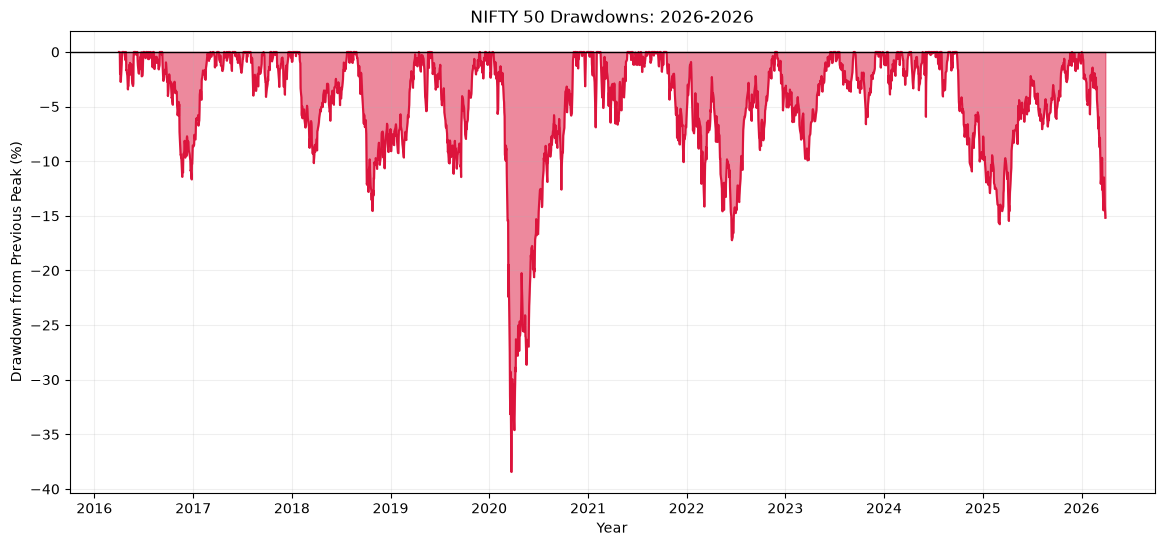

In [140]:
# Visual 

plt.figure(figsize = (14,6))

plt.plot(
        df['Date'],
        df['Drawdown_Pct'],
        color = 'crimson'
)

plt.fill_between (
    df['Date'],
    df['Drawdown_Pct'],
    0,
    color = 'crimson',
    alpha = 0.5
)

plt.axhline(0, color = 'black', linewidth = 1)

plt.title('NIFTY 50 Drawdowns: 2026-2026')
plt.xlabel('Year')
plt.ylabel('Drawdown from Previous Peak (%)')

plt.grid(alpha = 0.2)

plt.show()

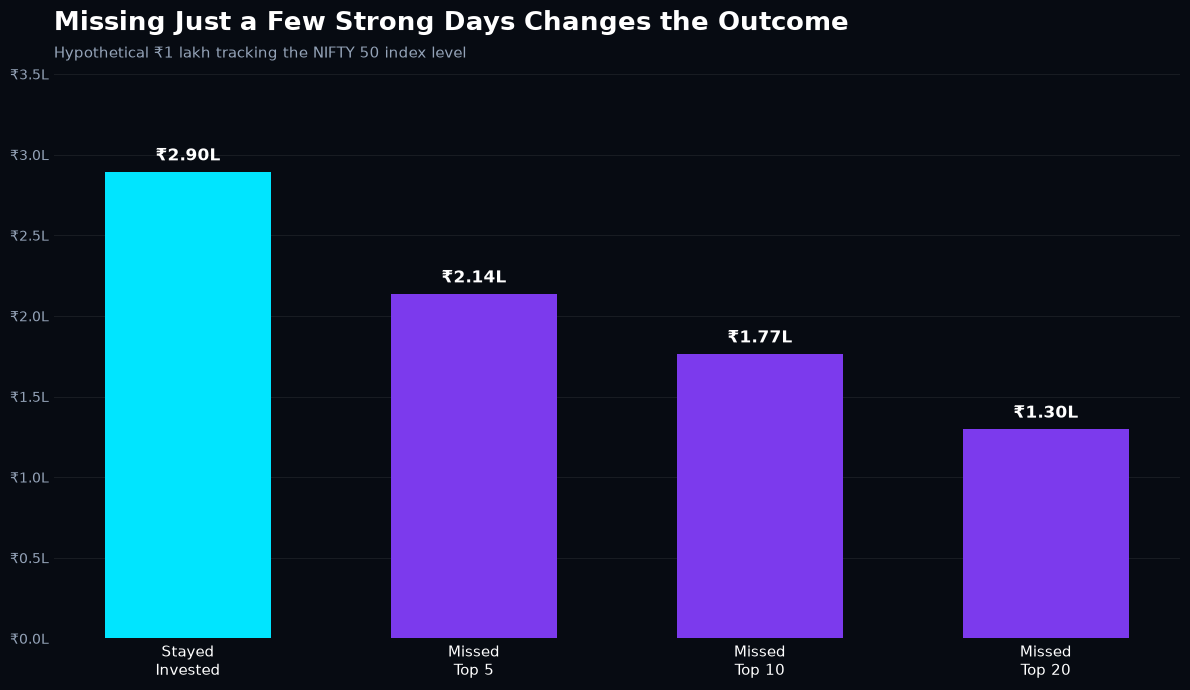

Saved to: ../visuals/nifty50_missing_strongest_days.png


In [158]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Data
labels = ["Stayed\nInvested", "Missed\nTop 5", "Missed\nTop 10", "Missed\nTop 20"]
values = [fully_invested_value, miss_5, miss_10, miss_20]

# Colours
bg = "#070B12"
cyan = "#00E5FF"
purple = "#7C3AED"
white = "#F8FAFC"
grey = "#94A3B8"

fig, ax = plt.subplots(figsize=(12, 7))

fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)

# Bars
bars = ax.bar(
    labels,
    values,
    color=[cyan, purple, purple, purple],
    width=0.58
)

# Title + subtitle
ax.set_title(
    "Missing Just a Few Strong Days Changes the Outcome",
    color="white",
    fontsize=19,
    fontweight="bold",
    loc="left",
    pad=28
)

ax.text(
    0,
    1.02,
    "Hypothetical ₹1 lakh tracking the NIFTY 50 index level",
    transform=ax.transAxes,
    color=grey,
    fontsize=11
)

# Y-axis as lakhs
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"₹{x/100000:.1f}L")
)

ax.tick_params(axis="x", colors="white", labelsize=11, length=0)
ax.tick_params(axis="y", colors=grey, labelsize=10, length=0)

# Very subtle grid
ax.grid(
    axis="y",
    color="white",
    alpha=0.07,
    linewidth=0.8
)

ax.set_axisbelow(True)

# Remove borders
for spine in ax.spines.values():
    spine.set_visible(False)

# Value labels
for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 7000,
        f"₹{value/100000:.2f}L",
        ha="center",
        color="white",
        fontsize=12,
        fontweight="bold"
    )

# Give labels breathing room
ax.set_ylim(0, max(values) * 1.22)

plt.tight_layout()

output_file = Path(
    "../visuals/nifty50_missing_strongest_days.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Saved to:", output_file)

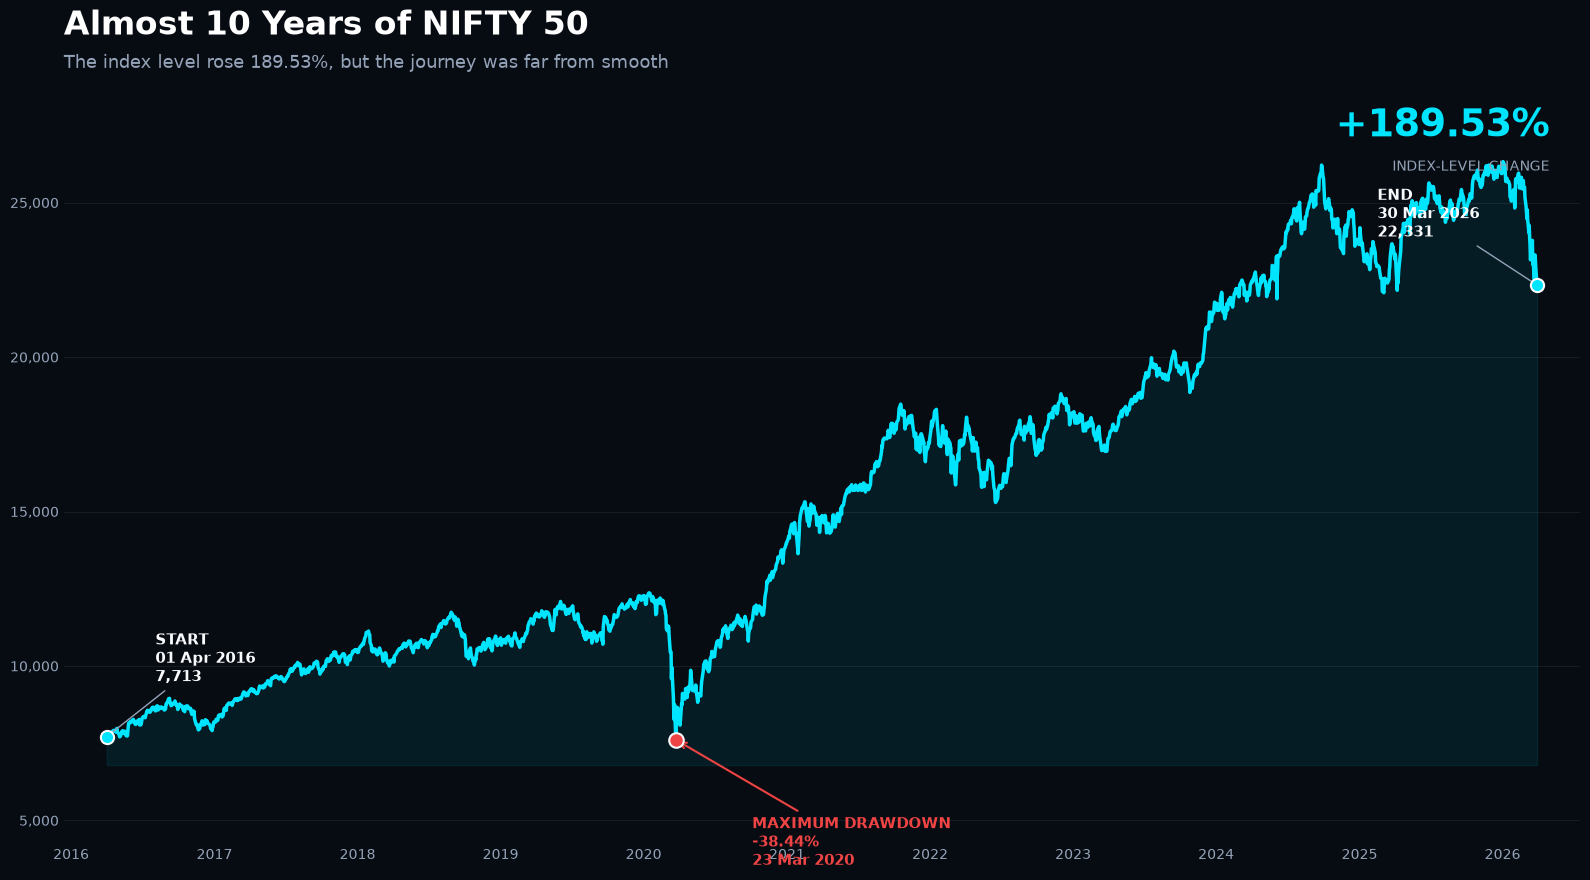

Saved to: ../visuals/nifty50_10_year_journey.png


In [150]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from pathlib import Path

# ---------------------------------------------
# COLOURS
# ---------------------------------------------
bg = "#070B12"
cyan = "#00E5FF"
red = "#EF4444"
white = "#F8FAFC"
grey = "#94A3B8"

# ---------------------------------------------
# CREATE FIGURE
# ---------------------------------------------
fig, ax = plt.subplots(figsize=(16, 9))

fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)

# ---------------------------------------------
# MAIN NIFTY 50 LINE
# ---------------------------------------------
ax.plot(
    df["Date"],
    df["Close"],
    color=cyan,
    linewidth=2.5
)

# Subtle fill below the line
ax.fill_between(
    df["Date"],
    df["Close"],
    df["Close"].min() * 0.90,
    color=cyan,
    alpha=0.08
)

# ---------------------------------------------
# IMPORTANT POINTS
# ---------------------------------------------

# Starting point
ax.scatter(
    start_date,
    start_close,
    color=cyan,
    s=90,
    edgecolor=white,
    linewidth=1.5,
    zorder=5
)

# Ending point
ax.scatter(
    end_date,
    end_close,
    color=cyan,
    s=90,
    edgecolor=white,
    linewidth=1.5,
    zorder=5
)

# Maximum drawdown bottom
ax.scatter(
    bottom_date,
    bottom_close,
    color=red,
    s=110,
    edgecolor=white,
    linewidth=1.5,
    zorder=6
)

# ---------------------------------------------
# ANNOTATIONS
# ---------------------------------------------

# Start
ax.annotate(
    f"START\n{start_date:%d %b %Y}\n{start_close:,.0f}",
    xy=(start_date, start_close),
    xytext=(35, 40),
    textcoords="offset points",
    color=white,
    fontsize=11,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="-",
        color=grey,
        linewidth=1
    )
)

# End
ax.annotate(
    f"END\n{end_date:%d %b %Y}\n{end_close:,.0f}",
    xy=(end_date, end_close),
    xytext=(-115, 35),
    textcoords="offset points",
    color=white,
    fontsize=11,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="-",
        color=grey,
        linewidth=1
    )
)

# Maximum drawdown
ax.annotate(
    "MAXIMUM DRAWDOWN\n-38.44%\n23 Mar 2020",
    xy=(bottom_date, bottom_close),
    xytext=(55, -90),
    textcoords="offset points",
    color=red,
    fontsize=11,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        color=red,
        linewidth=1.5
    )
)

# ---------------------------------------------
# TITLE
# ---------------------------------------------
ax.set_title(
    "Almost 10 Years of NIFTY 50",
    loc="left",
    color="white",
    fontsize=24,
    fontweight="bold",
    pad=35
)

# Subtitle
ax.text(
    0,
    1.02,
    "The index level rose 189.53%, but the journey was far from smooth",
    transform=ax.transAxes,
    color=grey,
    fontsize=13
)

# ---------------------------------------------
# HERO NUMBER
# ---------------------------------------------
ax.text(
    0.98,
    0.93,
    "+189.53%",
    transform=ax.transAxes,
    ha="right",
    color=cyan,
    fontsize=27,
    fontweight="bold"
)

ax.text(
    0.98,
    0.885,
    "INDEX-LEVEL CHANGE",
    transform=ax.transAxes,
    ha="right",
    color=grey,
    fontsize=10
)

# ---------------------------------------------
# X-AXIS
# ---------------------------------------------
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# ---------------------------------------------
# Y-AXIS
# ---------------------------------------------
ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"{x:,.0f}"
    )
)

# ---------------------------------------------
# AXIS APPEARANCE
# ---------------------------------------------
ax.tick_params(
    axis="x",
    colors=grey,
    labelsize=10,
    length=0
)

ax.tick_params(
    axis="y",
    colors=grey,
    labelsize=10,
    length=0
)

# Subtle grid
ax.grid(
    axis="y",
    color="white",
    alpha=0.07,
    linewidth=0.8
)

ax.set_axisbelow(True)

# Remove borders
for spine in ax.spines.values():
    spine.set_visible(False)

# Give chart some breathing room
ax.margins(
    x=0.03,
    y=0.13
)

# ---------------------------------------------
# SAVE VISUAL
# ---------------------------------------------
plt.tight_layout()

output_file = Path(
    "../visuals/nifty50_10_year_journey.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

# ---------------------------------------------
# SHOW
# ---------------------------------------------
plt.show()

print("Saved to:", output_file)

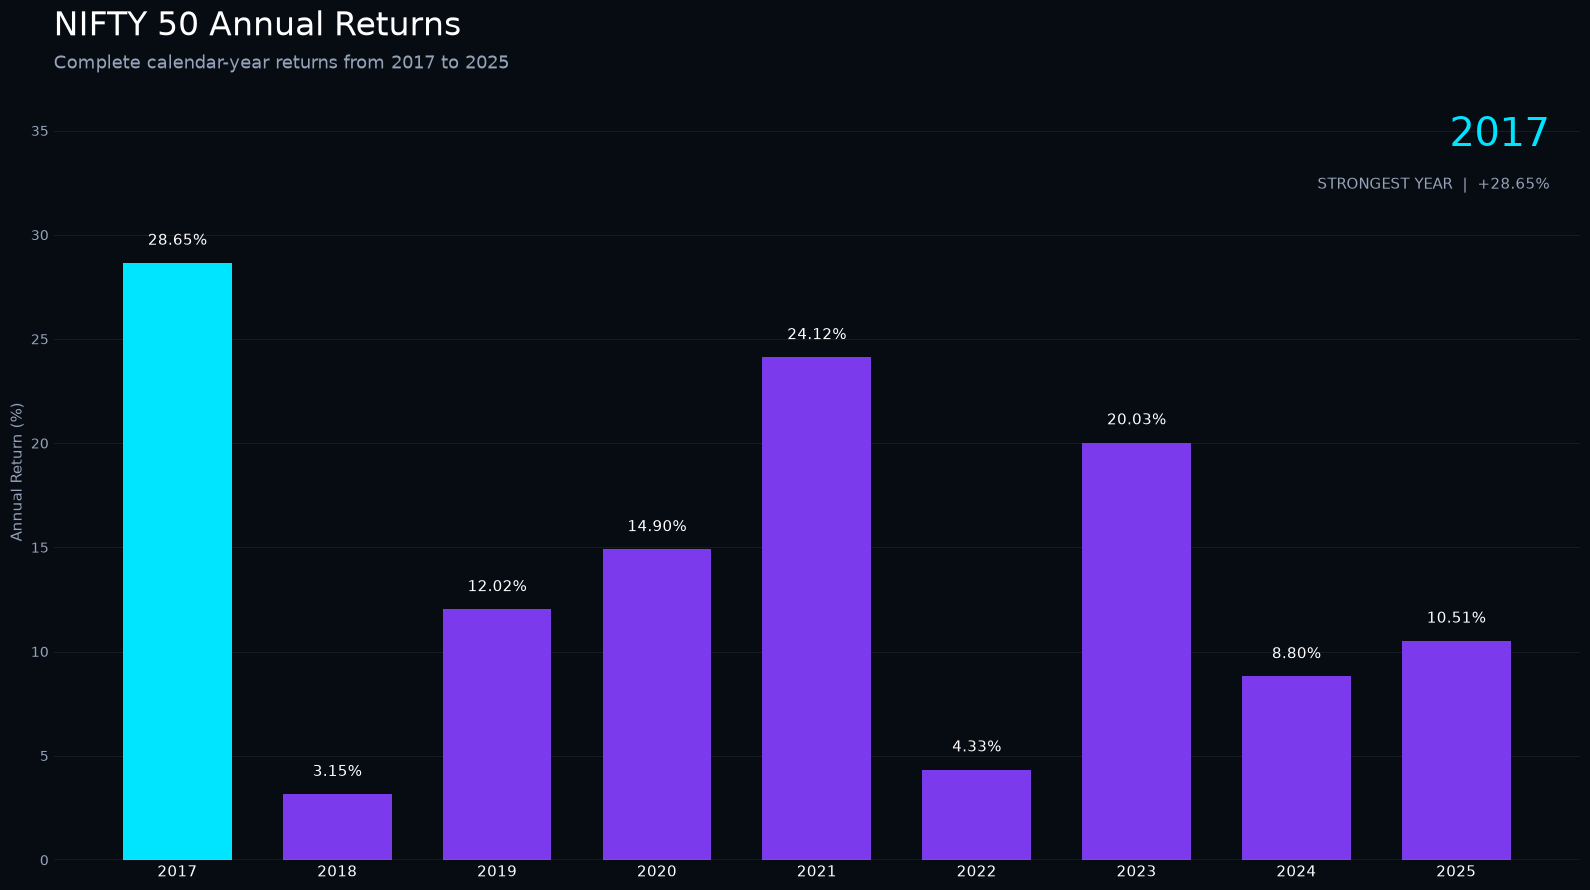

Saved to: ../visuals/nifty50_annual_returns.png


In [151]:
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------------------------------------
# PREPARE DATA
# ---------------------------------------------
years = complete_annual_returns.index.year
returns_values = complete_annual_returns.values

best_year_position = returns_values.argmax()

# ---------------------------------------------
# COLOURS
# ---------------------------------------------
bg = "#070B12"
cyan = "#00E5FF"
purple = "#7C3AED"
white = "#F8FAFC"
grey = "#94A3B8"

bar_colours = [
    cyan if i == best_year_position else purple
    for i in range(len(years))
]

# ---------------------------------------------
# CREATE FIGURE
# ---------------------------------------------
fig, ax = plt.subplots(figsize=(16, 9))

fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)

# ---------------------------------------------
# CREATE BARS
# ---------------------------------------------
bars = ax.bar(
    years,
    returns_values,
    color=bar_colours,
    width=0.68
)

# ---------------------------------------------
# TITLE AND SUBTITLE
# ---------------------------------------------
ax.set_title(
    "NIFTY 50 Annual Returns",
    loc="left",
    color="white",
    fontsize=24,
    pad=35
)

ax.text(
    0,
    1.02,
    "Complete calendar-year returns from 2017 to 2025",
    transform=ax.transAxes,
    color=grey,
    fontsize=13
)

# ---------------------------------------------
# VALUE LABELS
# ---------------------------------------------
for bar, value in zip(bars, returns_values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.7,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        color="white",
        fontsize=11
    )

# ---------------------------------------------
# HIGHLIGHT THE BEST YEAR
# ---------------------------------------------
best_year_value = returns_values[best_year_position]
best_year_number = years[best_year_position]

ax.text(
    0.98,
    0.92,
    f"{best_year_number}",
    transform=ax.transAxes,
    ha="right",
    color=cyan,
    fontsize=29
)

ax.text(
    0.98,
    0.865,
    f"STRONGEST YEAR  |  +{best_year_value:.2f}%",
    transform=ax.transAxes,
    ha="right",
    color=grey,
    fontsize=11
)

# ---------------------------------------------
# AXIS FORMATTING
# ---------------------------------------------
ax.set_xticks(years)

ax.tick_params(
    axis="x",
    colors="white",
    labelsize=11,
    length=0
)

ax.tick_params(
    axis="y",
    colors=grey,
    labelsize=10,
    length=0
)

ax.set_ylabel(
    "Annual Return (%)",
    color=grey,
    fontsize=11
)

ax.axhline(
    0,
    color="white",
    linewidth=1,
    alpha=0.30
)

# ---------------------------------------------
# GRID AND BORDERS
# ---------------------------------------------
ax.grid(
    axis="y",
    color="white",
    alpha=0.07,
    linewidth=0.8
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

# Extra space above labels
ax.set_ylim(
    0,
    max(returns_values) * 1.30
)

# ---------------------------------------------
# SAVE VISUAL
# ---------------------------------------------
plt.tight_layout()

output_file = Path(
    "../visuals/nifty50_annual_returns.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

# ---------------------------------------------
# SHOW VISUAL
# ---------------------------------------------
plt.show()

print("Saved to:", output_file)

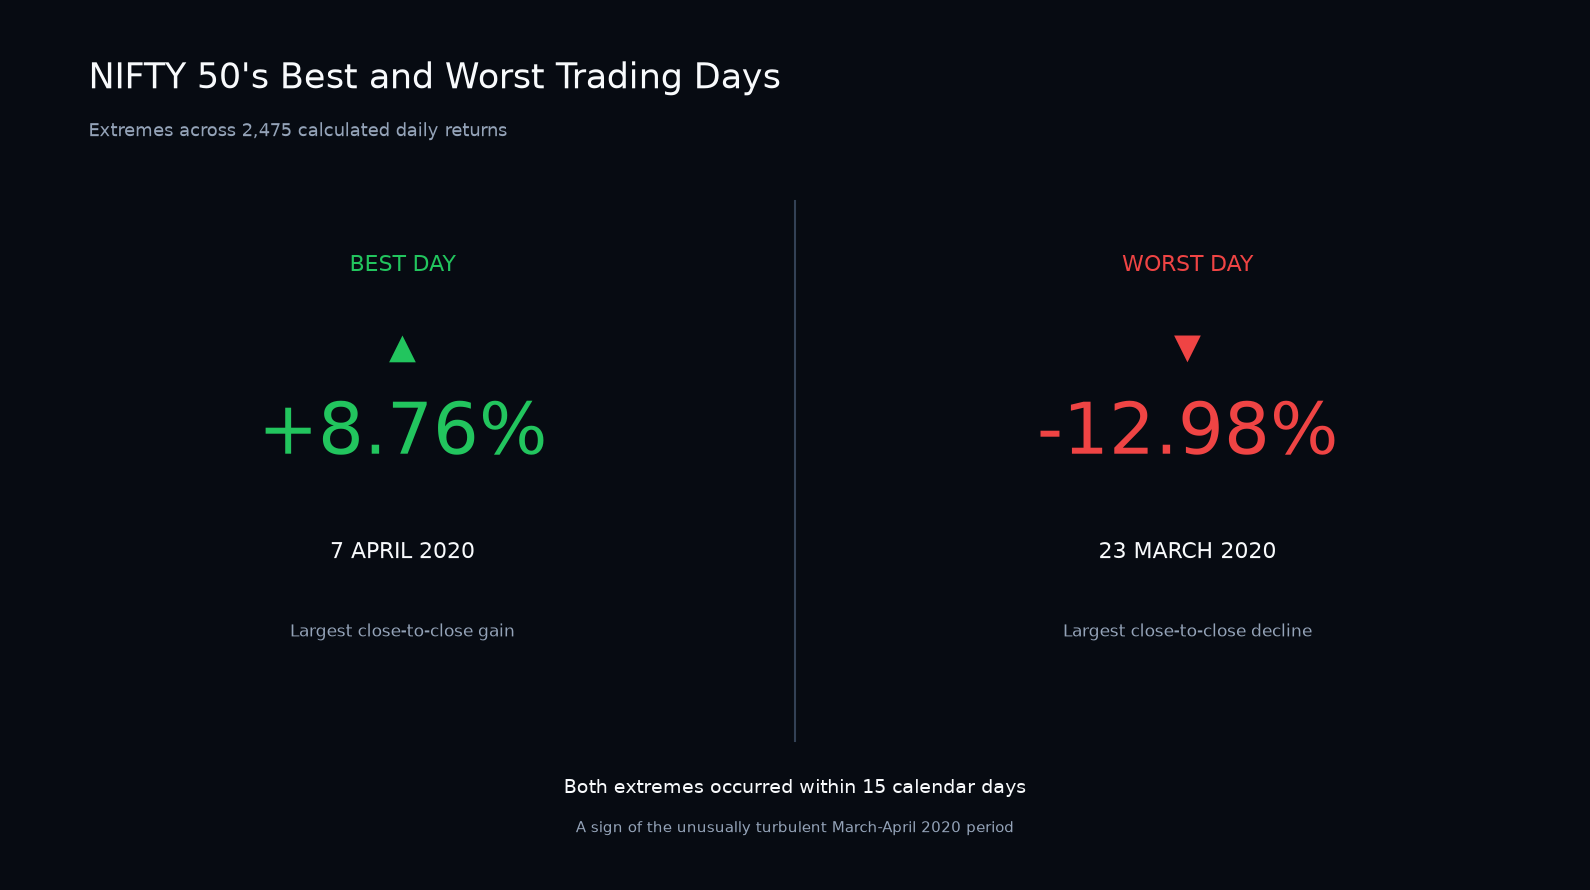

Saved to: ../visuals/nifty50_best_vs_worst_day.png


In [153]:
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------------------------------------
# COLOURS
# ---------------------------------------------
bg = "#070B12"
green = "#22C55E"
red = "#EF4444"
white = "#F8FAFC"
grey = "#94A3B8"
divider = "#334155"

# ---------------------------------------------
# CREATE FIGURE
# ---------------------------------------------
fig, ax = plt.subplots(figsize=(16, 9))

fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)

# Use a simple 0-to-1 coordinate system
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

# Hide axes completely
ax.axis("off")

# ---------------------------------------------
# TITLE AND SUBTITLE
# ---------------------------------------------
ax.text(
    0.05,
    0.91,
    "NIFTY 50's Best and Worst Trading Days",
    color=white,
    fontsize=25
)

ax.text(
    0.05,
    0.855,
    "Extremes across 2,475 calculated daily returns",
    color=grey,
    fontsize=13
)

# ---------------------------------------------
# CENTRE DIVIDER
# ---------------------------------------------
ax.plot(
    [0.50, 0.50],
    [0.16, 0.78],
    color=divider,
    linewidth=1.5
)

# ---------------------------------------------
# BEST DAY: LEFT SIDE
# ---------------------------------------------
ax.text(
    0.25,
    0.70,
    "BEST DAY",
    ha="center",
    color=green,
    fontsize=16
)

ax.text(
    0.25,
    0.49,
    "+8.76%",
    ha="center",
    color=green,
    fontsize=52
)

ax.text(
    0.25,
    0.37,
    "7 APRIL 2020",
    ha="center",
    color=white,
    fontsize=16
)

ax.text(
    0.25,
    0.28,
    "Largest close-to-close gain",
    ha="center",
    color=grey,
    fontsize=12
)

# Up indicator
ax.text(
    0.25,
    0.60,
    "▲",
    ha="center",
    color=green,
    fontsize=25
)

# ---------------------------------------------
# WORST DAY: RIGHT SIDE
# ---------------------------------------------
ax.text(
    0.75,
    0.70,
    "WORST DAY",
    ha="center",
    color=red,
    fontsize=16
)

ax.text(
    0.75,
    0.49,
    "-12.98%",
    ha="center",
    color=red,
    fontsize=52
)

ax.text(
    0.75,
    0.37,
    "23 MARCH 2020",
    ha="center",
    color=white,
    fontsize=16
)

ax.text(
    0.75,
    0.28,
    "Largest close-to-close decline",
    ha="center",
    color=grey,
    fontsize=12
)

# Down indicator
ax.text(
    0.75,
    0.60,
    "▼",
    ha="center",
    color=red,
    fontsize=25
)

# ---------------------------------------------
# BOTTOM INSIGHT
# ---------------------------------------------
ax.text(
    0.50,
    0.10,
    "Both extremes occurred within 15 calendar days",
    ha="center",
    color=white,
    fontsize=14
)

ax.text(
    0.50,
    0.055,
    "A sign of the unusually turbulent March-April 2020 period",
    ha="center",
    color=grey,
    fontsize=11
)

# ---------------------------------------------
# SAVE VISUAL
# ---------------------------------------------
plt.tight_layout()

output_file = Path(
    "../visuals/nifty50_best_vs_worst_day.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

# ---------------------------------------------
# SHOW VISUAL
# ---------------------------------------------
plt.show()

print("Saved to:", output_file)

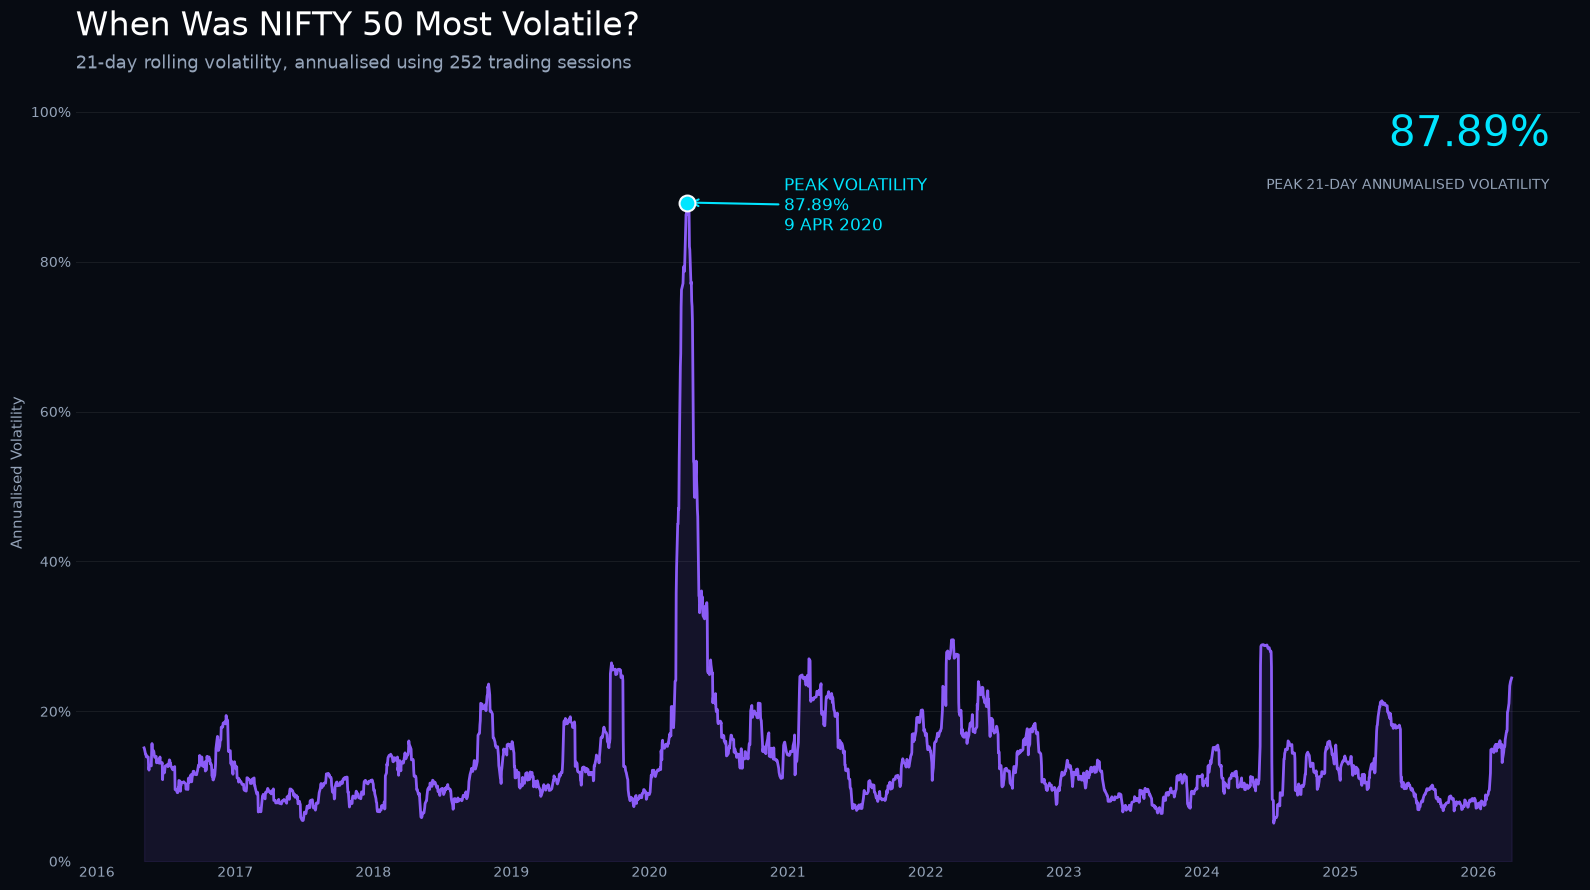

Saved to: ../visuals/nifty50_rolling_volatility.png


In [154]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from pathlib import Path

# ---------------------------------------------
# COLOURS
# ---------------------------------------------
bg = "#070B12"
purple = "#8B5CF6"
cyan = "#00E5FF"
white = "#F8FAFC"
grey = "#94A3B8"

# ---------------------------------------------
# CREATE FIGURE
# ---------------------------------------------
fig, ax = plt.subplots(figsize=(16, 9))

fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)

# ---------------------------------------------
# VOLATILITY LINE
# ---------------------------------------------
ax.plot(
    df["Date"],
    df["Rolling_Volatility_21D"],
    color=purple,
    linewidth=2
)

ax.fill_between(
    df["Date"],
    df["Rolling_Volatility_21D"],
    0,
    color=purple,
    alpha=0.10
)

# ---------------------------------------------
# PEAK VOLATILITY POINT
# ---------------------------------------------
ax.scatter(
    peak_volatility_date,
    peak_volatility,
    color=cyan,
    s=130,
    edgecolor=white,
    linewidth=1.5,
    zorder=5
)

# Peak annotation
ax.annotate(
    "PEAK VOLATILITY\n87.89%\n9 APR 2020",
    xy=(peak_volatility_date, peak_volatility),
    xytext=(70, -20),
    textcoords="offset points",
    color=cyan,
    fontsize=12,
    arrowprops=dict(
        arrowstyle="->",
        color=cyan,
        linewidth=1.5
    )
)

# ---------------------------------------------
# TITLE
# ---------------------------------------------
ax.set_title(
    "When Was NIFTY 50 Most Volatile?",
    loc="left",
    color="white",
    fontsize=24,
    pad=35
)

ax.text(
    0,
    1.02,
    "21-day rolling volatility, annualised using 252 trading sessions",
    transform=ax.transAxes,
    color=grey,
    fontsize=13
)

# ---------------------------------------------
# HERO NUMBER
# ---------------------------------------------
ax.text(
    0.98,
    0.92,
    "87.89%",
    transform=ax.transAxes,
    ha="right",
    color=cyan,
    fontsize=30
)

ax.text(
    0.98,
    0.865,
    "PEAK 21-DAY ANNUMALISED VOLATILITY",
    transform=ax.transAxes,
    ha="right",
    color=grey,
    fontsize=10
)

# ---------------------------------------------
# X AXIS
# ---------------------------------------------
ax.xaxis.set_major_locator(
    mdates.YearLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

# ---------------------------------------------
# Y AXIS
# ---------------------------------------------
ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"{x:.0f}%"
    )
)

ax.set_ylabel(
    "Annualised Volatility",
    color=grey,
    fontsize=11
)

# ---------------------------------------------
# AXIS STYLING
# ---------------------------------------------
ax.tick_params(
    axis="x",
    colors=grey,
    labelsize=10,
    length=0
)

ax.tick_params(
    axis="y",
    colors=grey,
    labelsize=10,
    length=0
)

ax.grid(
    axis="y",
    color="white",
    alpha=0.07,
    linewidth=0.8
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_ylim(
    0,
    max(df["Rolling_Volatility_21D"].dropna()) * 1.18
)

# ---------------------------------------------
# SAVE
# ---------------------------------------------
plt.tight_layout()

output_file = Path(
    "../visuals/nifty50_rolling_volatility.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

# ---------------------------------------------
# SHOW
# ---------------------------------------------
plt.show()

print("Saved to:", output_file)

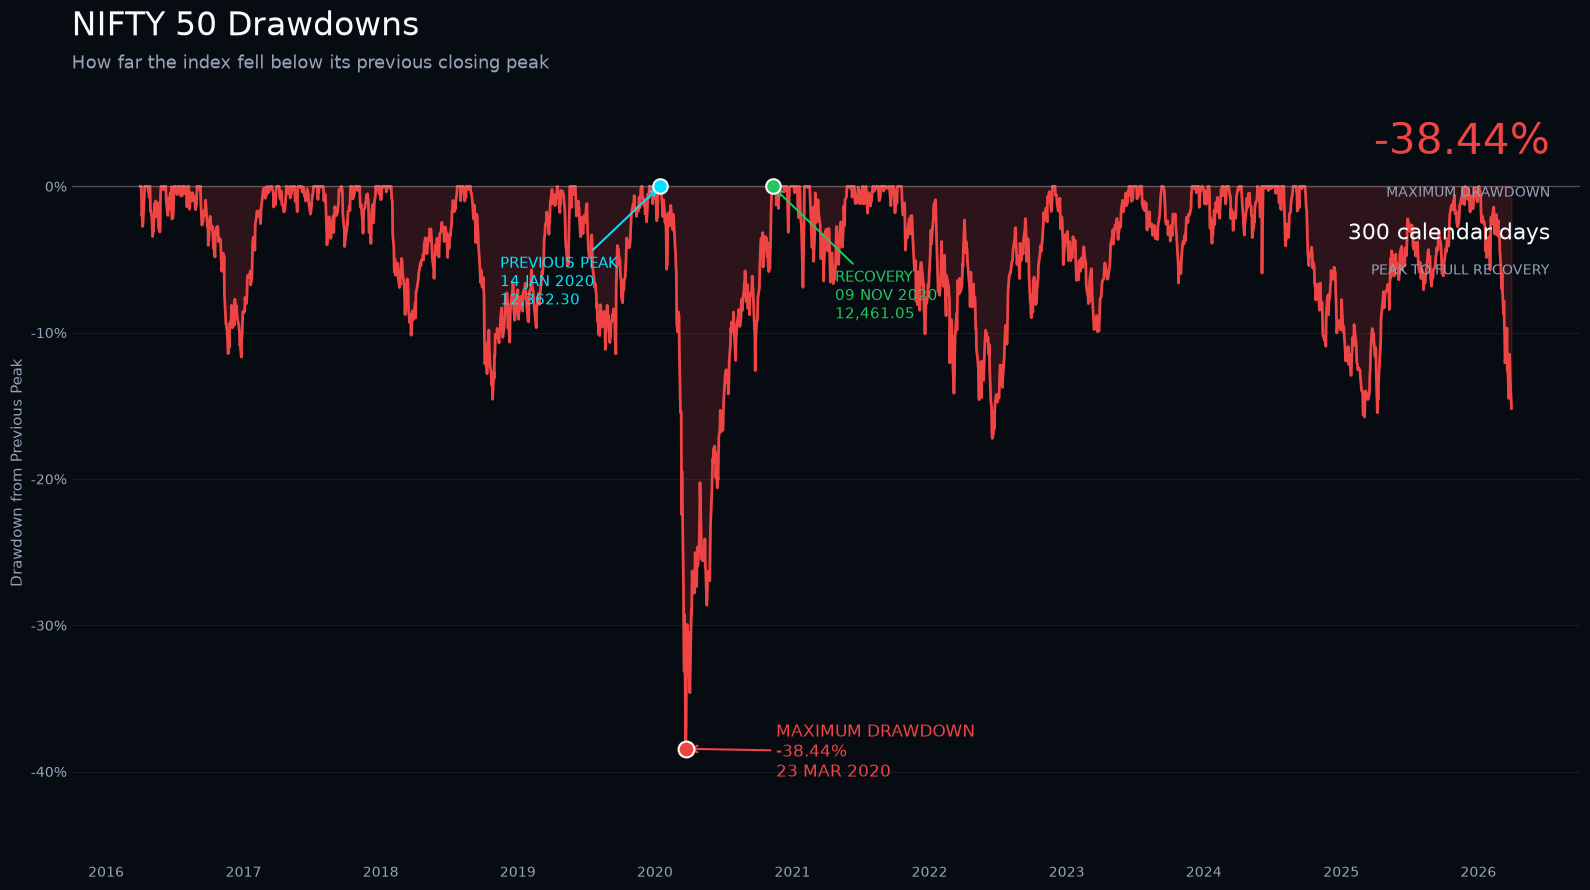

Saved to: ../visuals/nifty50_drawdowns.png


In [157]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from pathlib import Path

# ---------------------------------------------
# COLOURS
# ---------------------------------------------
bg = "#070B12"
red = "#EF4444"
cyan = "#00E5FF"
green = "#22C55E"
white = "#F8FAFC"
grey = "#94A3B8"

# ---------------------------------------------
# CREATE FIGURE
# ---------------------------------------------
fig, ax = plt.subplots(figsize=(16, 9))

fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)

# ---------------------------------------------
# DRAWDOWN LINE AND AREA
# ---------------------------------------------
ax.plot(
    df["Date"],
    df["Drawdown_Pct"],
    color=red,
    linewidth=2
)

ax.fill_between(
    df["Date"],
    df["Drawdown_Pct"],
    0,
    color=red,
    alpha=0.16
)

ax.axhline(
    0,
    color=white,
    linewidth=1,
    alpha=0.25
)

# ---------------------------------------------
# KEY POINTS
# ---------------------------------------------

# Peak before the drawdown
ax.scatter(
    peak_date,
    0,
    color=cyan,
    s=110,
    edgecolor=white,
    linewidth=1.5,
    zorder=5
)

# Maximum drawdown bottom
ax.scatter(
    bottom_date,
    df.loc[bottom_idx, "Drawdown_Pct"],
    color=red,
    s=130,
    edgecolor=white,
    linewidth=1.5,
    zorder=6
)

# Recovery point
ax.scatter(
    recovery_date,
    0,
    color=green,
    s=110,
    edgecolor=white,
    linewidth=1.5,
    zorder=5
)

# ---------------------------------------------
# ANNOTATIONS
# ---------------------------------------------

ax.annotate(
    f"PREVIOUS PEAK\n{peak_date:%d JAN 2020}\n12,362.30",
    xy=(peak_date, 0),
    xytext=(-115, -85),
    textcoords="offset points",
    color=cyan,
    fontsize=11,
    arrowprops=dict(
        arrowstyle="->",
        color=cyan,
        linewidth=1.4
    )
)

ax.annotate(
    "MAXIMUM DRAWDOWN\n-38.44%\n23 MAR 2020",
    xy=(bottom_date, df.loc[bottom_idx, "Drawdown_Pct"]),
    xytext=(65, -20),
    textcoords="offset points",
    color=red,
    fontsize=12,
    arrowprops=dict(
        arrowstyle="->",
        color=red,
        linewidth=1.5
    )
)

ax.annotate(
    f"RECOVERY\n{recovery_date:%d NOV 2020}\n12,461.05",
    xy=(recovery_date, 0),
    xytext=(45, -95),
    textcoords="offset points",
    color=green,
    fontsize=11,
    arrowprops=dict(
        arrowstyle="->",
        color=green,
        linewidth=1.4
    )
)

# ---------------------------------------------
# TITLE AND SUBTITLE
# ---------------------------------------------
ax.set_title(
    "NIFTY 50 Drawdowns",
    loc="left",
    color=white,
    fontsize=24,
    pad=35
)

ax.text(
    0,
    1.02,
    "How far the index fell below its previous closing peak",
    transform=ax.transAxes,
    color=grey,
    fontsize=13
)

# ---------------------------------------------
# HERO NUMBER
# ---------------------------------------------
ax.text(
    0.98,
    0.91,
    "-38.44%",
    transform=ax.transAxes,
    ha="right",
    color=red,
    fontsize=30
)

ax.text(
    0.98,
    0.855,
    "MAXIMUM DRAWDOWN",
    transform=ax.transAxes,
    ha="right",
    color=grey,
    fontsize=10
)

ax.text(
    0.98,
    0.80,
    "300 calendar days",
    transform=ax.transAxes,
    ha="right",
    color=white,
    fontsize=16
)

ax.text(
    0.98,
    0.755,
    "PEAK TO FULL RECOVERY",
    transform=ax.transAxes,
    ha="right",
    color=grey,
    fontsize=10
)

# ---------------------------------------------
# AXIS FORMATTING
# ---------------------------------------------
ax.xaxis.set_major_locator(
    mdates.YearLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"{x:.0f}%"
    )
)

ax.set_ylabel(
    "Drawdown from Previous Peak",
    color=grey,
    fontsize=11
)

# ---------------------------------------------
# AXIS STYLING
# ---------------------------------------------
ax.tick_params(
    axis="x",
    colors=grey,
    labelsize=10,
    length=0
)

ax.tick_params(
    axis="y",
    colors=grey,
    labelsize=10,
    length=0
)

ax.grid(
    axis="y",
    color=white,
    alpha=0.07,
    linewidth=0.8
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_ylim(
    min(df["Drawdown_Pct"]) * 1.20,
    7
)

# ---------------------------------------------
# SAVE
# ---------------------------------------------
plt.tight_layout()

output_file = Path(
    "../visuals/nifty50_drawdowns.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

# ---------------------------------------------
# SHOW
# ---------------------------------------------
plt.show()

print("Saved to:", output_file)